# Retail Sales Data Cleaning and Analysis

**Prepared by:** Okewu Jeremiah

**Objective:** To inspect, clean, transform, and analyze retail transaction data using Python and pandas.

**Dataset note:** This is synthetic Nigerian retail data created for practice. It does not represent verified transactions from actual companies.

In [36]:

!pip -q install datasets

import pandas as pd
from datasets import load_dataset

# Load a sample of 50,000 retail transactions
dataset = load_dataset(
    "AhmadBabajoytk/nigerian_retail_and_ecommerce_point_of_sale_records",
    split="train[:50000]"
)

# Convert the dataset into a pandas DataFrame
df = dataset.to_pandas()

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Number of rows and columns: (50000, 11)


,transaction_id,store_name,city,transaction_date,cashier_id,items_count,total_amount_ngn,payment_method,discount_applied,loyalty_points_earned,receipt_number
0,POS00000000,Balogun Market,Kano,2024-08-03 16:00:00,CASH990,13,33837.28,cash,False,662,RCP0000000000
1,POS00000001,Game,Kano,2024-09-07 20:00:00,CASH840,2,23883.91,cash,False,531,RCP0000000001
2,POS00000002,Game,Port Harcourt,2024-07-04 09:00:00,CASH148,19,35400.49,mobile_money,False,840,RCP0000000002
3,POS00000003,Ebeano,Port Harcourt,2024-09-05 19:00:00,CASH809,5,10287.57,cash,False,610,RCP0000000003
4,POS00000004,Computer Village,Ilorin,2024-10-08 08:00:00,CASH876,18,189802.63,cash,False,391,RCP0000000004


## Step 2: Data Inspection

In this step, I will inspect the retail dataset to understand its structure, column names, data types, missing values, duplicate records, and statistical summary before cleaning the data.

In [37]:

# 1. Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# 2. Check the number of rows and columns
print("\nDATASET SHAPE:")
print(df.shape)

# 3. Check data types and non-null counts
print("\nDATASET INFORMATION:")
df.info()

# 4. Display the first five records
print("\nFIRST FIVE ROWS:")
display(df.head())


COLUMN NAMES:
['transaction_id', 'store_name', 'city', 'transaction_date', 'cashier_id', 'items_count', 'total_amount_ngn', 'payment_method', 'discount_applied', 'loyalty_points_earned', 'receipt_number']

DATASET SHAPE:
(50000, 11)

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         50000 non-null  object 
 1   store_name             50000 non-null  object 
 2   city                   50000 non-null  object 
 3   transaction_date       50000 non-null  object 
 4   cashier_id             50000 non-null  object 
 5   items_count            50000 non-null  int64  
 6   total_amount_ngn       50000 non-null  float64
 7   payment_method         50000 non-null  object 
 8   discount_applied       50000 non-null  bool   
 9   loyalty_points_earned  50000 non-null  int64  
 10  receipt

,transaction_id,store_name,city,transaction_date,cashier_id,items_count,total_amount_ngn,payment_method,discount_applied,loyalty_points_earned,receipt_number
0,POS00000000,Balogun Market,Kano,2024-08-03 16:00:00,CASH990,13,33837.28,cash,False,662,RCP0000000000
1,POS00000001,Game,Kano,2024-09-07 20:00:00,CASH840,2,23883.91,cash,False,531,RCP0000000001
2,POS00000002,Game,Port Harcourt,2024-07-04 09:00:00,CASH148,19,35400.49,mobile_money,False,840,RCP0000000002
3,POS00000003,Ebeano,Port Harcourt,2024-09-05 19:00:00,CASH809,5,10287.57,cash,False,610,RCP0000000003
4,POS00000004,Computer Village,Ilorin,2024-10-08 08:00:00,CASH876,18,189802.63,cash,False,391,RCP0000000004


In [38]:

# Count missing values in each column
print("MISSING VALUES:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

# Count unique values in each column
print("\nUNIQUE VALUES:")
print(df.nunique())


MISSING VALUES:
transaction_id           0
store_name               0
city                     0
transaction_date         0
cashier_id               0
items_count              0
total_amount_ngn         0
payment_method           0
discount_applied         0
loyalty_points_earned    0
receipt_number           0
dtype: int64

DUPLICATE ROWS:
0

UNIQUE VALUES:
transaction_id           50000
store_name                  10
city                        15
transaction_date          4214
cashier_id                 900
items_count                 20
total_amount_ngn         49938
payment_method               3
discount_applied             2
loyalty_points_earned     1001
receipt_number           50000
dtype: int64


### Observation — Initial Data Inspection

The dataset contains 50,000 retail transaction records. The initial inspection found no missing values and no fully duplicated rows. Transaction IDs and receipt numbers each have 50,000 unique values. The dataset includes 10 store names, 15 cities, and 3 payment methods.

Although these results suggest that the dataset is complete at the initial inspection stage, further validation is necessary to identify invalid dates, unusual transaction amounts, inconsistent values, and potential business-rule violations.

**Conclusion:** The dataset is ready for further quality checks, but it should not yet be considered fully cleaned.

In [39]:

# 1. Check the data types
print("DATA TYPES:")
print(df.dtypes)

# 2. Convert the transaction date to datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"], errors="coerce"
)

# 3. Check invalid dates
print("\nINVALID DATES:")
print(df["transaction_date"].isna().sum())

# 4. Check negative or zero transaction amounts
print("\nZERO OR NEGATIVE AMOUNTS:")
print((df["total_amount_ngn"] <= 0).sum())

# 5. Check negative or zero item counts
print("\nZERO OR NEGATIVE ITEM COUNTS:")
print((df["items_count"] <= 0).sum())

# 6. View numerical statistics
print("\nNUMERICAL SUMMARY:")
display(df.describe())


DATA TYPES:
transaction_id            object
store_name                object
city                      object
transaction_date          object
cashier_id                object
items_count                int64
total_amount_ngn         float64
payment_method            object
discount_applied            bool
loyalty_points_earned      int64
receipt_number            object
dtype: object

INVALID DATES:
0

ZERO OR NEGATIVE AMOUNTS:
0

ZERO OR NEGATIVE ITEM COUNTS:
0

NUMERICAL SUMMARY:


,transaction_date,items_count,total_amount_ngn,loyalty_points_earned
count,50000,50000.000000,50000.000000,50000.000000
mean,2024-05-30 14:56:39.192000,10.521420,99979.273058,502.704220
min,2024-01-01 08:00:00,1.000000,1012.820000,0.000000
25%,2024-03-16 16:00:00,6.000000,50697.695000,251.000000
50%,2024-05-30 11:00:00,11.000000,99433.885000,504.000000
75%,2024-08-14 11:00:00,16.000000,149417.860000,755.000000
max,2024-10-27 21:00:00,20.000000,199996.690000,1000.000000
std,NaN,5.776308,57301.379858,289.703338


### Observation — Data Type and Validity Checks

The transaction date was initially stored as an object (text) data type and was converted to datetime. No invalid dates were detected after conversion. All transaction amounts and item counts were positive.

The average transaction amount was approximately ₦99,979.27, with a minimum of ₦1,012.82 and a maximum of ₦199,996.69. These results describe the synthetic sample only.

Further investigation is needed to identify potential outliers and assess whether unusually high or low values are valid.

In [40]:

# Check potential outliers using the IQR method

columns_to_check = [
    "total_amount_ngn",
    "items_count",
    "loyalty_points_earned"
]

for column in columns_to_check:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nColumn: {column}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Potential outliers:", len(outliers))



Column: total_amount_ngn
Lower bound: -97382.55
Upper bound: 297498.11
Potential outliers: 0

Column: items_count
Lower bound: -9.0
Upper bound: 31.0
Potential outliers: 0

Column: loyalty_points_earned
Lower bound: -505.0
Upper bound: 1511.0
Potential outliers: 0


In [41]:

# Confirm the date coverage
print("Earliest transaction:", df["transaction_date"].min())
print("Latest transaction:", df["transaction_date"].max())

# Total sales in the sample
print("Total sales (NGN):", round(df["total_amount_ngn"].sum(), 2))

# Average transaction value
print("Average transaction value (NGN):",
      round(df["total_amount_ngn"].mean(), 2))

# Number of transactions by payment method
print("\nTransactions by payment method:")
display(df["payment_method"].value_counts())

# Sales by payment method
print("\nSales by payment method:")
display(
    df.groupby("payment_method")["total_amount_ngn"]
      .agg(["count", "sum", "mean"])
      .round(2)
)


Earliest transaction: 2024-01-01 08:00:00
Latest transaction: 2024-10-27 21:00:00
Total sales (NGN): 4998963652.92
Average transaction value (NGN): 99979.27

Transactions by payment method:


,count
payment_method,
cash,25084
card,19900
mobile_money,5016



Sales by payment method:


,count,sum,mean
payment_method,,,
card,19900,2.001128e+09,100559.20
cash,25084,2.503763e+09,99815.14
mobile_money,5016,4.940725e+08,98499.31


## Step 12: Data Transformation and Monthly Sales Analysis

In this step, I will transform the transaction date into monthly periods and group the data to identify changes in sales activity over time. This will help demonstrate how pandas can turn transaction-level data into useful business summaries.

In [42]:

# Create a monthly period column
df["month"] = df["transaction_date"].dt.to_period("M").astype(str)

# Summarize monthly sales performance
monthly_sales = (
    df.groupby("month")
    .agg(
        total_transactions=("transaction_id", "count"),
        total_sales_ngn=("total_amount_ngn", "sum"),
        average_transaction_ngn=("total_amount_ngn", "mean")
    )
    .reset_index()
)

# Format the results for easier reading
monthly_sales["total_sales_ngn"] = monthly_sales["total_sales_ngn"].round(2)
monthly_sales["average_transaction_ngn"] = (
    monthly_sales["average_transaction_ngn"].round(2)
)

display(monthly_sales)


,month,total_transactions,total_sales_ngn,average_transaction_ngn
0,2024-01,5063,4.977589e+08,98313.03
1,2024-02,4821,4.836237e+08,100316.06
2,2024-03,5294,5.274534e+08,99632.30
3,2024-04,4930,4.906694e+08,99527.27
4,2024-05,5157,5.185509e+08,100552.81
5,2024-06,4968,5.007047e+08,100785.97
6,2024-07,5040,5.027790e+08,99757.73
7,2024-08,5282,5.310901e+08,100547.17
8,2024-09,4970,5.017986e+08,100965.52
9,2024-10,4475,4.445349e+08,99337.41


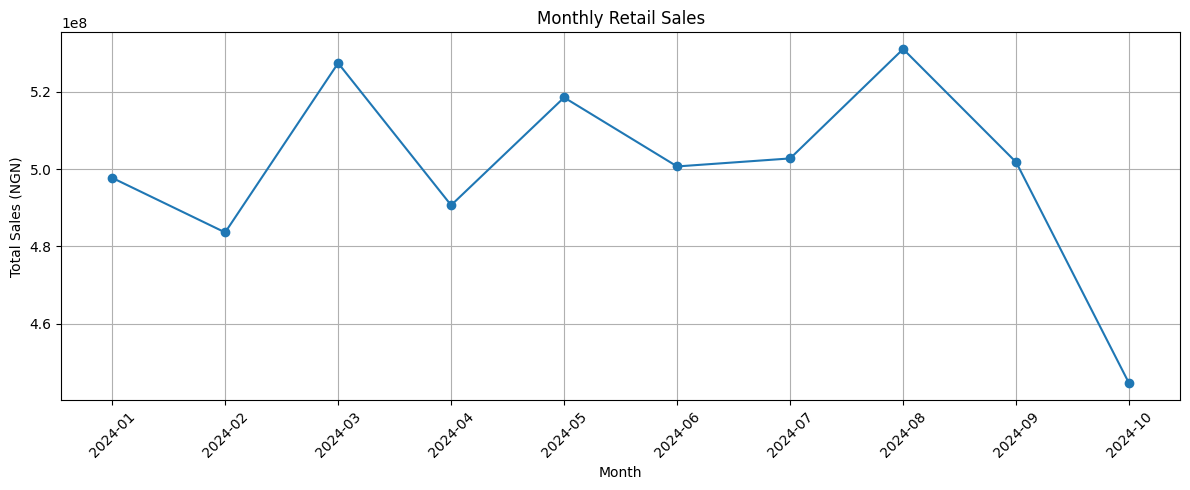

In [43]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["total_sales_ngn"],
    marker="o"
)

plt.title("Monthly Retail Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales (NGN)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


## Step 13: Store Performance Analysis

The purpose of this analysis is to compare retail stores by transaction volume, total sales, and average transaction value. The results can help identify high-performing stores and locations that may require further investigation.

The dataset is synthetic, so the findings demonstrate an analytical method rather than verified performance by actual businesses.

In [44]:

# Summarize performance by store
store_performance = (
    df.groupby("store_name")
    .agg(
        total_transactions=("transaction_id", "count"),
        total_sales_ngn=("total_amount_ngn", "sum"),
        average_transaction_ngn=("total_amount_ngn", "mean")
    )
    .reset_index()
)

# Sort stores from highest to lowest total sales
store_performance = store_performance.sort_values(
    by="total_sales_ngn",
    ascending=False
)

# Round currency figures
store_performance["total_sales_ngn"] = (
    store_performance["total_sales_ngn"].round(2)
)

store_performance["average_transaction_ngn"] = (
    store_performance["average_transaction_ngn"].round(2)
)

display(store_performance)


,store_name,total_transactions,total_sales_ngn,average_transaction_ngn
1,Computer Village,5082,5.142213e+08,101184.83
0,Balogun Market,5037,5.068516e+08,100625.69
9,Spar,5057,5.066911e+08,100195.98
3,Game,5042,5.060961e+08,100376.06
4,Justrite,5059,5.047525e+08,99773.19
6,Pointek,5013,5.031030e+08,100359.67
2,Ebeano,4932,4.929681e+08,99952.99
7,Shoprite,4933,4.911038e+08,99554.80
8,Slot,4953,4.870047e+08,98325.19
5,Mr Price,4892,4.861714e+08,99380.91


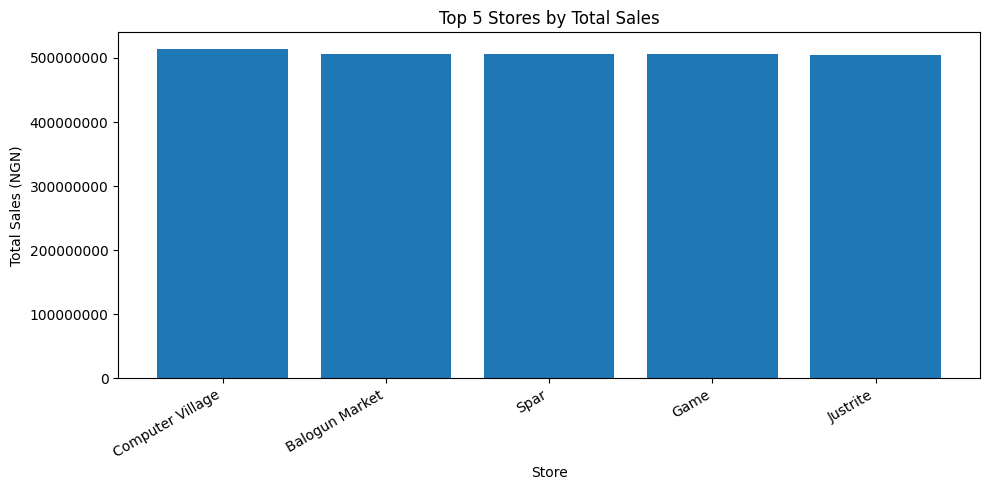

In [45]:

import matplotlib.pyplot as plt

top_5_stores = store_performance.head(5)

plt.figure(figsize=(10, 5))

plt.bar(
    top_5_stores["store_name"],
    top_5_stores["total_sales_ngn"]
)

plt.title("Top 5 Stores by Total Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales (NGN)")
plt.xticks(rotation=30, ha="right")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


### Observation — Store Performance Analysis

The store performance analysis ranked ten store names by total transaction value.

Computer Village recorded the highest total sales at approximately ₦514.22 million across 5,082 transactions. Mr Price recorded the lowest total sales at approximately ₦486.17 million across 4,892 transactions.

The difference between the highest- and lowest-performing stores was approximately ₦28.05 million.

**Business implication:** Store-level reporting can help identify performance differences and guide further investigation. Additional information would be required to explain the causes of those differences.

**Data limitation:** The dataset is synthetic and must not be treated as verified company sales data.

In [46]:

# Summarize sales by city
city_performance = (
    df.groupby("city")
    .agg(
        total_transactions=("transaction_id", "count"),
        total_sales_ngn=("total_amount_ngn", "sum"),
        average_transaction_ngn=("total_amount_ngn", "mean")
    )
    .reset_index()
)

# Rank cities by total sales
city_performance = city_performance.sort_values(
    by="total_sales_ngn",
    ascending=False
)

# Format the results
city_performance["total_sales_ngn"] = (
    city_performance["total_sales_ngn"].round(2)
)

city_performance["average_transaction_ngn"] = (
    city_performance["average_transaction_ngn"].round(2)
)

display(city_performance)


,city,total_transactions,total_sales_ngn,average_transaction_ngn
4,Calabar,3460,3.485172e+08,100727.50
10,Kano,3444,3.439254e+08,99862.20
5,Enugu,3353,3.391632e+08,101152.16
2,Abuja,3400,3.385314e+08,99568.05
3,Benin City,3339,3.382627e+08,101306.58
9,Kaduna,3374,3.378739e+08,100140.47
6,Ibadan,3346,3.377627e+08,100945.22
8,Jos,3401,3.359048e+08,98766.49
11,Lagos,3340,3.339220e+08,99976.64
13,Port Harcourt,3293,3.332836e+08,101209.72


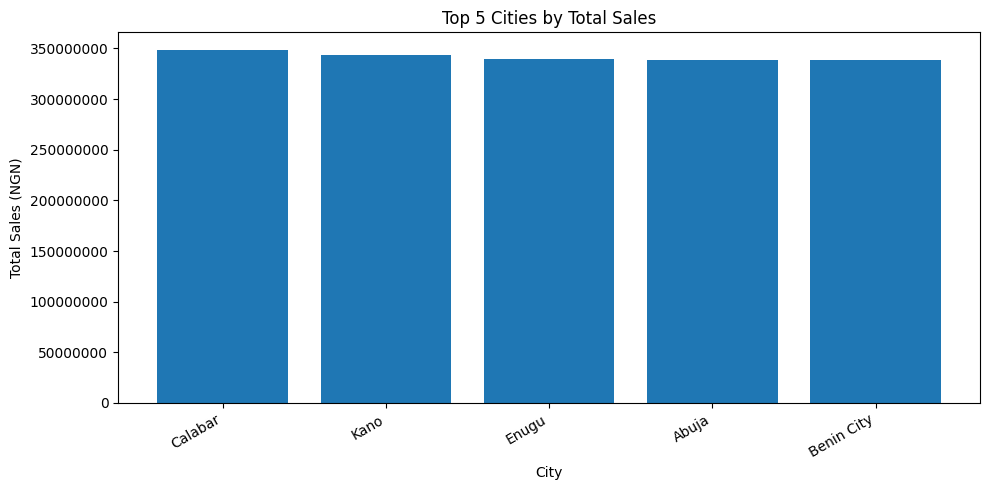

In [47]:

import matplotlib.pyplot as plt

top_5_cities = city_performance.head(5)

plt.figure(figsize=(10, 5))

plt.bar(
    top_5_cities["city"],
    top_5_cities["total_sales_ngn"]
)

plt.title("Top 5 Cities by Total Sales")
plt.xlabel("City")
plt.ylabel("Total Sales (NGN)")
plt.xticks(rotation=30, ha="right")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


### Observation — City Performance Analysis

The analysis compared 15 cities using transaction counts, total transaction values, and average transaction values.

Calabar recorded the highest total sales at approximately ₦348.52 million across 3,460 transactions. Aba recorded the lowest total sales at approximately ₦313.51 million across 3,139 transactions.

The difference in total sales between these two cities was approximately ₦35.01 million.

**Business implication:** Geographic sales analysis can help businesses compare markets and identify locations for further investigation.

**Limitation:** The dataset is synthetic. These results demonstrate an analytical method and are not evidence of actual sales performance in these cities.

In [48]:

# Create a separate copy for the cleaned dataset
cleaned_df = df.copy()

# Check data quality before exporting
print("Rows before export:", len(cleaned_df))
print("Missing values:", cleaned_df.isnull().sum().sum())
print("Duplicate rows:", cleaned_df.duplicated().sum())

# Confirm that dates are stored correctly
print("Transaction date data type:",
      cleaned_df["transaction_date"].dtype)

# Save the cleaned dataset as a CSV file
cleaned_df.to_csv(
    "nigerian_retail_cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")


Rows before export: 50000
Missing values: 0
Duplicate rows: 0
Transaction date data type: datetime64[ns]

Cleaned dataset saved successfully!


In [49]:

from google.colab import files

files.download("nigerian_retail_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:

# Create a summary of sales by payment method
payment_summary = (
    df.groupby("payment_method")
    .agg(
        total_transactions=("transaction_id", "count"),
        total_sales_ngn=("total_amount_ngn", "sum"),
        average_transaction_ngn=("total_amount_ngn", "mean")
    )
    .reset_index()
    .round(2)
)

# Create a data quality summary
quality_summary = pd.DataFrame({
    "Check": [
        "Total rows",
        "Missing values",
        "Duplicate rows",
        "Invalid transaction dates",
        "Zero or negative transaction amounts",
        "Zero or negative item counts"
    ],
    "Result": [
        len(df),
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df["transaction_date"].isna().sum(),
        (df["total_amount_ngn"] <= 0).sum(),
        (df["items_count"] <= 0).sum()
    ]
})

# Export the results into one Excel workbook
with pd.ExcelWriter("retail_sales_analysis.xlsx") as writer:
    cleaned_df.to_excel(writer, sheet_name="Cleaned Data", index=False)
    monthly_sales.to_excel(writer, sheet_name="Monthly Sales", index=False)
    store_performance.to_excel(writer, sheet_name="Store Performance", index=False)
    city_performance.to_excel(writer, sheet_name="City Performance", index=False)
    payment_summary.to_excel(writer, sheet_name="Payment Summary", index=False)
    quality_summary.to_excel(writer, sheet_name="Data Quality", index=False)

print("Excel workbook created successfully!")
print("Sheets: Cleaned Data, Monthly Sales, Store Performance, City Performance, Payment Summary, Data Quality")

display(payment_summary)
display(quality_summary)


Excel workbook created successfully!
Sheets: Cleaned Data, Monthly Sales, Store Performance, City Performance, Payment Summary, Data Quality


,payment_method,total_transactions,total_sales_ngn,average_transaction_ngn
0,card,19900,2.001128e+09,100559.20
1,cash,25084,2.503763e+09,99815.14
2,mobile_money,5016,4.940725e+08,98499.31


,Check,Result
0,Total rows,50000
1,Missing values,0
2,Duplicate rows,0
3,Invalid transaction dates,0
4,Zero or negative transaction amounts,0
5,Zero or negative item counts,0


In [51]:

from google.colab import files

files.download("retail_sales_analysis.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
!pip install reportlab

# Retail Sales Data Analysis Report

**Prepared by:** Okewu Jeremiah

**Tools:** Python, pandas, Matplotlib, Excel

**Project objective:** Demonstrate data cleaning, validation, transformation, exploratory analysis, and business reporting using a synthetic Nigerian retail transaction dataset.

**Dataset:** A sample of 50,000 generated transactions from 2024.

**Important limitation:** The dataset is synthetic and does not represent verified transactions from real companies.

In [53]:

import os
import matplotlib.pyplot as plt

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image, PageBreak
)

# Create the output folder
os.makedirs("retail_report_assets", exist_ok=True)

# Prepare summary figures
total_transactions = len(df)
total_sales = df["total_amount_ngn"].sum()
average_sale = df["total_amount_ngn"].mean()
top_store = store_performance.iloc[0]
lowest_store = store_performance.iloc[-1]
top_city = city_performance.iloc[0]
lowest_city = city_performance.iloc[-1]
top_month = monthly_sales.loc[monthly_sales["total_sales_ngn"].idxmax()]
lowest_month = monthly_sales.loc[monthly_sales["total_sales_ngn"].idxmin()]

# Chart 1: Monthly sales
monthly_chart = "retail_report_assets/monthly_sales.png"
plt.figure(figsize=(9, 4))
plt.plot(
    monthly_sales["month"],
    monthly_sales["total_sales_ngn"] / 1_000_000,
    marker="o"
)
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales (NGN millions)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(monthly_chart, dpi=160)
plt.close()

# Chart 2: Top five stores
store_chart = "retail_report_assets/top_stores.png"
top5 = store_performance.head(5).sort_values("total_sales_ngn")
plt.figure(figsize=(9, 4))
plt.barh(
    top5["store_name"],
    top5["total_sales_ngn"] / 1_000_000
)
plt.title("Top Five Stores by Sales")
plt.xlabel("Sales (NGN millions)")
plt.tight_layout()
plt.savefig(store_chart, dpi=160)
plt.close()

# Chart 3: Payment method sales
payment_chart = "retail_report_assets/payment_methods.png"
payment_summary = (
    df.groupby("payment_method")
    .agg(
        transactions=("transaction_id", "count"),
        sales=("total_amount_ngn", "sum")
    )
    .reset_index()
)
plt.figure(figsize=(8, 4))
plt.bar(
    payment_summary["payment_method"],
    payment_summary["sales"] / 1_000_000
)
plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Sales (NGN millions)")
plt.tight_layout()
plt.savefig(payment_chart, dpi=160)
plt.close()

# Set up the PDF
pdf_file = "Okewu_Jeremiah_Retail_Sales_Report.pdf"
doc = SimpleDocTemplate(
    pdf_file,
    pagesize=A4,
    rightMargin=1.8 * cm,
    leftMargin=1.8 * cm,
    topMargin=1.8 * cm,
    bottomMargin=1.8 * cm
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontSize=22,
    leading=28,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    spaceAfter=12
))
styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading2"],
    textColor=colors.HexColor("#17365D"),
    spaceBefore=12,
    spaceAfter=7
))
styles.add(ParagraphStyle(
    name="SmallText",
    parent=styles["BodyText"],
    fontSize=8,
    leading=11
))

story = []

# Cover and executive summary
story.append(Paragraph(
    "Retail Sales Data Cleaning<br/>and Analysis",
    styles["ReportTitle"]
))
story.append(Paragraph(
    "<b>Prepared by:</b> Okewu Jeremiah<br/>"
    "<b>Tools:</b> Python, pandas, Matplotlib and Excel<br/>"
    "<b>Dataset:</b> 50,000 synthetic retail transactions",
    styles["Normal"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("Executive Summary", styles["SectionHeading"]))
story.append(Paragraph(
    f"The analysis covered {total_transactions:,} transaction records "
    f"with a combined transaction value of NGN {total_sales:,.2f}. "
    f"The average transaction value was NGN {average_sale:,.2f}. "
    "The work included data inspection, date conversion, validity checks, "
    "outlier screening, and sales analysis by month, store, city and payment method.",
    styles["BodyText"]
))

metrics = [
    ["Metric", "Result"],
    ["Transaction records", f"{total_transactions:,}"],
    ["Total transaction value", f"NGN {total_sales:,.2f}"],
    ["Average transaction value", f"NGN {average_sale:,.2f}"],
    ["Missing values detected initially", "0"],
    ["Exact duplicate rows detected initially", "0"]
]
metric_table = Table(metrics, colWidths=[8 * cm, 8 * cm])
metric_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 6),
    ("VALIGN", (0, 0), (-1, -1), "TOP")
]))
story.append(Spacer(1, 8))
story.append(metric_table)

# Data quality
story.append(Paragraph("1. Data Quality and Preparation", styles["SectionHeading"]))
story.append(Paragraph(
    "The initial inspection found no missing values or fully duplicated rows. "
    "The transaction date column was converted from text to datetime. "
    "No invalid dates, non-positive transaction amounts, or non-positive item "
    "counts were detected. The IQR method did not flag outliers in the three "
    "numeric columns tested. These checks do not prove that every value is correct.",
    styles["BodyText"]
))

# Monthly analysis
story.append(Paragraph("2. Monthly Sales Analysis", styles["SectionHeading"]))
story.append(Paragraph(
    f"{top_month['month']} had the highest monthly sales, at "
    f"NGN {top_month['total_sales_ngn']:,.2f}. "
    f"{lowest_month['month']} had the lowest, at "
    f"NGN {lowest_month['total_sales_ngn']:,.2f}. "
    "Monthly summaries help compare transaction activity over time.",
    styles["BodyText"]
))
story.append(Spacer(1, 8))
story.append(Image(monthly_chart, width=16 * cm, height=7.1 * cm))

# Store and city analysis
story.append(Paragraph("3. Store Performance", styles["SectionHeading"]))
story.append(Paragraph(
    f"{top_store['store_name']} ranked first by total sales at "
    f"NGN {top_store['total_sales_ngn']:,.2f}. "
    f"{lowest_store['store_name']} ranked last at "
    f"NGN {lowest_store['total_sales_ngn']:,.2f}. "
    "These rankings identify differences for further investigation, "
    "but do not explain why the differences occurred.",
    styles["BodyText"]
))
story.append(Spacer(1, 6))
story.append(Image(store_chart, width=16 * cm, height=7.1 * cm))

story.append(Paragraph("4. City Performance", styles["SectionHeading"]))
story.append(Paragraph(
    f"{top_city['city']} recorded the highest city-level sales at "
    f"NGN {top_city['total_sales_ngn']:,.2f}, while "
    f"{lowest_city['city']} recorded the lowest at "
    f"NGN {lowest_city['total_sales_ngn']:,.2f}. "
    "Further analysis would be required to understand the causes of these differences.",
    styles["BodyText"]
))

# Payment analysis
story.append(Paragraph("5. Payment Method Analysis", styles["SectionHeading"]))
cash_count = int(
    df["payment_method"].eq("cash").sum()
)
card_average = df.loc[
    df["payment_method"].eq("card"), "total_amount_ngn"
].mean()
story.append(Paragraph(
    f"Cash was the most frequent payment method, with {cash_count:,} transactions. "
    f"Card transactions had an average transaction value of NGN {card_average:,.2f}. "
    "Transaction frequency and average transaction value measure different aspects "
    "of payment behaviour.",
    styles["BodyText"]
))
story.append(Spacer(1, 8))
story.append(Image(payment_chart, width=15 * cm, height=7 * cm))

# Recommendations and limitations
story.append(Paragraph("6. Recommendations", styles["SectionHeading"]))
recommendations = [
    "Monitor monthly sales and transaction counts to identify changes in activity.",
    "Investigate store and city differences before making operational decisions.",
    "Track payment method usage to understand transaction preferences.",
    "Validate future datasets against business rules and investigate suspicious records.",
    "For a real company engagement, repeat the analysis using authorized, verified company data."
]
for recommendation in recommendations:
    story.append(Paragraph(
        "• " + recommendation,
        styles["BodyText"]
    ))
    story.append(Spacer(1, 4))

story.append(Paragraph("7. Scope and Limitations", styles["SectionHeading"]))
story.append(Paragraph(
    "The dataset is synthetic and covers transactions from January 1 to "
    "October 27, 2024. It does not cover the full 2018–2026 period and must "
    "not be interpreted as verified sales from actual businesses. Store and "
    "city names in the dataset do not establish real-world performance. "
    "No records were removed based on the checks performed in this project.",
    styles["SmallText"]
))
story.append(Spacer(1, 10))
story.append(Paragraph(
    "Prepared as a portfolio demonstration by Okewu Jeremiah.",
    styles["SmallText"]
))

def add_page_number(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawString(1.8 * cm, 1.0 * cm, "Retail Sales Analysis | Portfolio Project")
    canvas.drawRightString(
        A4[0] - 1.8 * cm, 1.0 * cm, f"Page {document.page}"
    )
    canvas.restoreState()

doc.build(story, onFirstPage=add_page_number, onLaterPages=add_page_number)

print("PDF report created:", pdf_file)
print("File size (bytes):", os.path.getsize(pdf_file))


PDF report created: Okewu_Jeremiah_Retail_Sales_Report.pdf
File size (bytes): 150632


In [54]:

from google.colab import files

files.download("Okewu_Jeremiah_Retail_Sales_Report.pdf")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>